## Introducción a la transformada Z

Dominio $z$ (Discreto): Estable si los polos están dentro del círculo unitario ($\vert{}z\vert{} < 1$).

$$X(z) = \sum_{n=-\infty}^{\infty} x[n]z^{-n}$$

## Symbolic Z-Transform with SymPy

In [1]:
import sympy as sp

In [2]:
# Define symbols: n (time index), z (complex variable), a (constant)
n, z, a = sp.symbols('n z a', positive=True)

In [3]:
# Example 1: Unit step function x[n] = 1 for n >= 0
x_step = 1
X_step = sp.summation(x_step * z**(-n), (n, 0, sp.oo))

print("Z-transform of unit step u[n]:")
sp.pprint(sp.simplify(X_step))

Z-transform of unit step u[n]:
⎧    z          1    
⎪  ─────    for ─ < 1
⎪  z - 1        z    
⎪                    
⎪  ∞                 
⎪ ___                
⎨ ╲                  
⎪  ╲    -n           
⎪  ╱   z    otherwise
⎪ ╱                  
⎪ ‾‾‾                
⎪n = 0               
⎩                    


In [4]:
# Example 2: Exponential sequence x[n] = a^n for n >= 0
x_exp = a**n
X_exp = sp.summation(x_exp * z**(-n), (n, 0, sp.oo))
print("\nZ-transform of a^n u[n]:")
sp.pprint(sp.simplify(X_exp))


Z-transform of a^n u[n]:
⎧     z            a    
⎪   ──────     for ─ < 1
⎪   -a + z         z    
⎪                       
⎪  ∞                    
⎪ ___                   
⎨ ╲                     
⎪  ╲    n  -n           
⎪  ╱   a ⋅z    otherwise
⎪ ╱                     
⎪ ‾‾‾                   
⎪n = 0                  
⎩                       


## Finding Poles, Zeros, and Checking Stability

$$H(z) = \frac{b_0 + b_1 z^{-1} + b_2 z^{-2} + \dots}{a_0 + a_1 z^{-1} + a_2 z^{-2} + \dots}$$

In [5]:
import numpy as np
from scipy import signal

# Define a transfer function: H(z) = (1 + 0.5z^-1) / (1 - 1.2z^-1 + 0.35z^-2)
b = [1.0, 0.5]         # Numerator coefficients (zeros)
a = [1.0, -1.2, 0.35]  # Denominator coefficients (poles)

# Convert transfer function to zeros, poles, and system gain
zeros, poles, gain = signal.tf2zpk(b, a)

print("Zeros:", zeros)
print("Poles:", poles)
print("Pole magnitudes:", np.abs(poles))

# Check stability
is_stable = np.all(np.abs(poles) < 1)
print("Is the system stable?", is_stable)

Zeros: [-0.5]
Poles: [0.7 0.5]
Pole magnitudes: [0.7 0.5]
Is the system stable? True


### Computing the Inverse Z-Transform (Impulse Response)

In [6]:
# Create a unit impulse: [1, 0, 0, 0, ...] of length 10
impulse = np.zeros(10)
impulse[0] = 1.0

# Compute the inverse Z-transform (time-domain response h[n])
h_n = signal.lfilter(b, a, impulse)

print("First 10 samples of h[n]:")
print(np.round(h_n, 4))

First 10 samples of h[n]:
[1.     1.7    1.69   1.433  1.1281 0.8522 0.6278 0.4551 0.3264 0.2324]


## Sistema de Primer Orden (Filtro Pasa-Bajas / Suavizado Exponencial)

Un sistema de 1er orden tiene un solo polo. Es el equivalente digital de un circuito RC y se usa mucho para suavizar señales ruidosas (como datos de sensores).

- Ecuación en diferencias:


$$y[n] = (1-\alpha)x[n] + \alpha y[n-1]$$

- Función de transferencia: 

$$H(z) = \frac{1 - \alpha}{1 - \alpha z^{-1}} = \frac{(1 - \alpha)z}{z - \alpha}$$

In [7]:
import numpy as np
from scipy import signal

# Coeficiente de suavizado (0 < alpha < 1 para que sea estable)
alpha = 0.8

b_1st = [1 - alpha]      # Numerador: (1 - alpha)
a_1st = [1.0, -alpha]    # Denominador: 1 - alpha*z^-1

# Analizar polos y respuesta al escalón
zeros, poles, _ = signal.tf2zpk(b_1st, a_1st)
print(f"1er Orden -> Polo en: {poles[0]:.2f} | Estable: {np.abs(poles[0]) < 1}")

# Respuesta a una entrada escalón (step response)
step_input = np.ones(15)
y_1st = signal.lfilter(b_1st, a_1st, step_input)
print("Salida ante escalón:", np.round(y_1st, 3))

1er Orden -> Polo en: 0.80 | Estable: True
Salida ante escalón: [0.2   0.36  0.488 0.59  0.672 0.738 0.79  0.832 0.866 0.893 0.914 0.931
 0.945 0.956 0.965]


In [8]:
from util_graphs import analizar_sistema

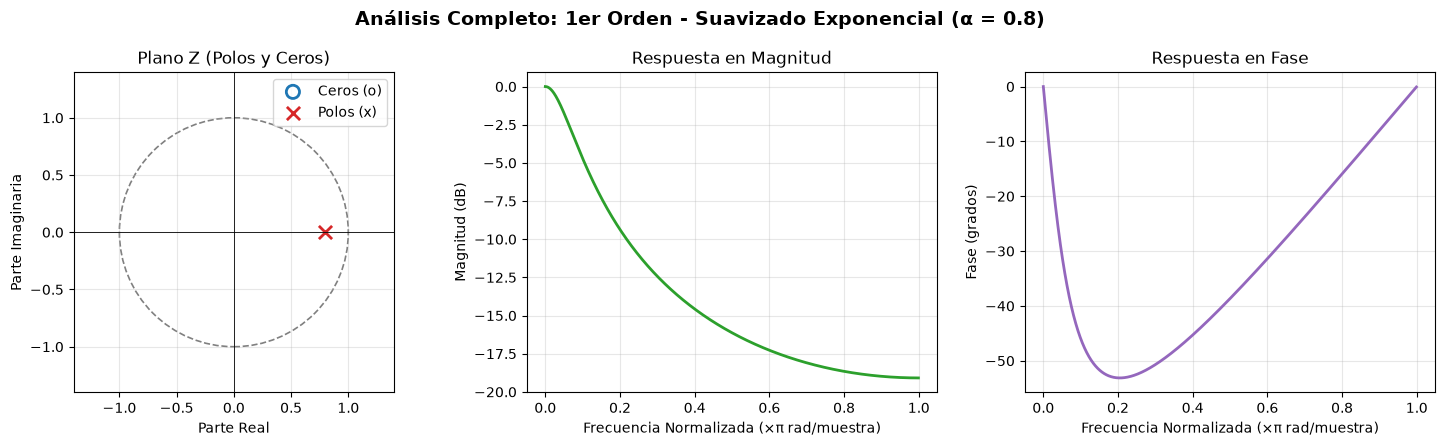

In [14]:
# 1. Sistema de 1er Orden (Filtro Pasa-Bajas Exponencial)
alpha = 0.8
b_1st = [1 - alpha]
a_1st = [1.0, -alpha]
analizar_sistema(b_1st, a_1st, "1er Orden - Suavizado Exponencial (α = 0.8)")

## 2. Sistema de 2do Orden (Resonador Subamortiguado)


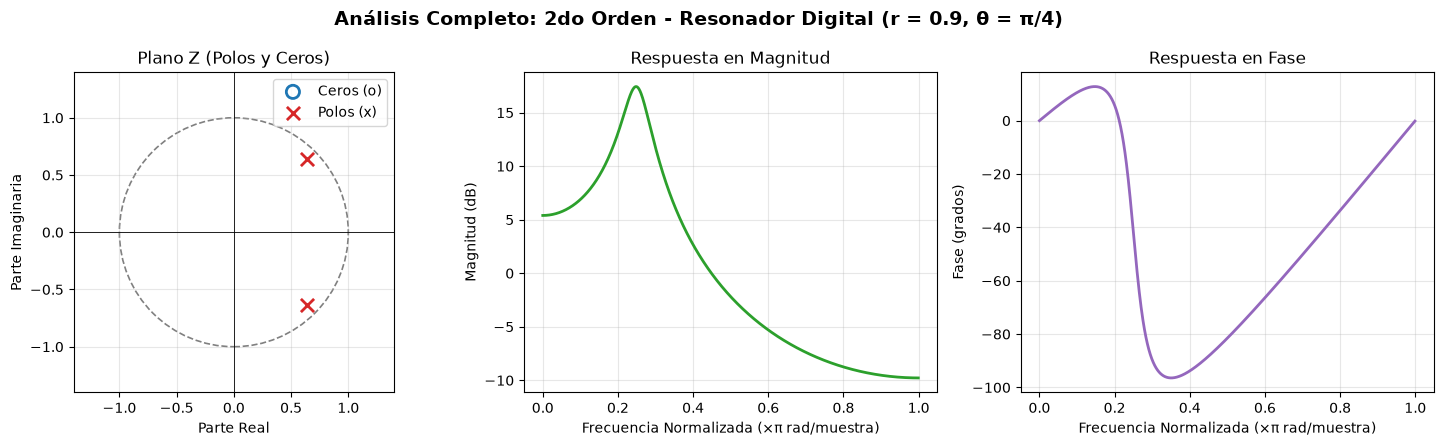

In [ ]:
r = 0.9
theta = np.pi / 4  # Resonancia en 0.25 * pi
b_2nd = [1.0]
a_2nd = [1.0, -2 * r * np.cos(theta), r**2]
analizar_sistema(b_2nd, a_2nd, "2do Orden - Resonador Digital (r = 0.9, θ = π/4)")

## 3. Sistema FIR de 4to Orden (Media Móvil de 5 puntos)


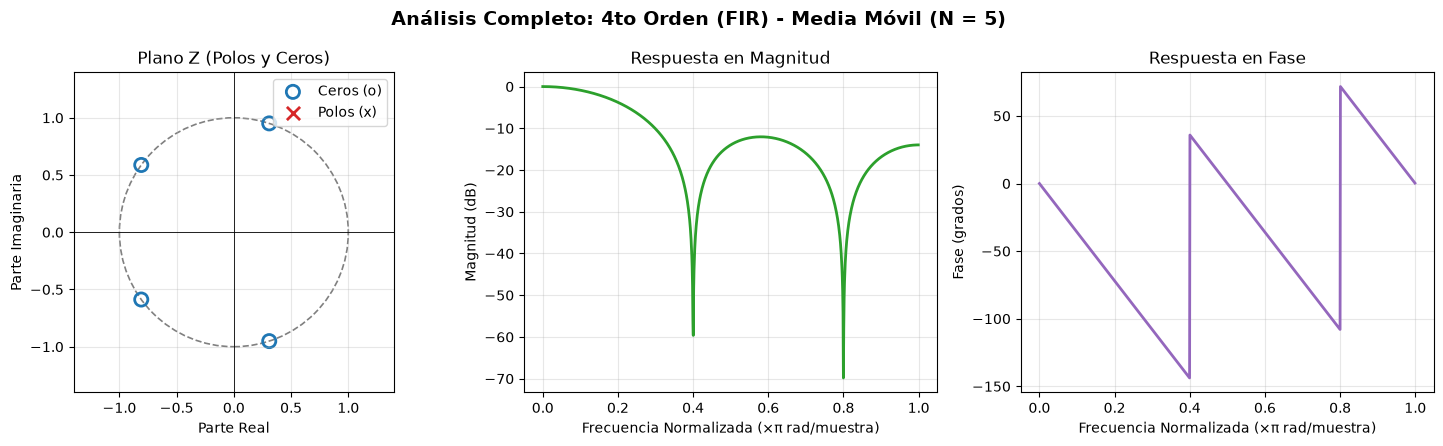

In [ ]:
N = 5
b_fir = np.ones(N) / N
a_fir = [1.0]
analizar_sistema(b_fir, a_fir, "4to Orden (FIR) - Media Móvil (N = 5)")

## 4. Sistema IIR de 4to Orden (Butterworth Pasa-Bajos)


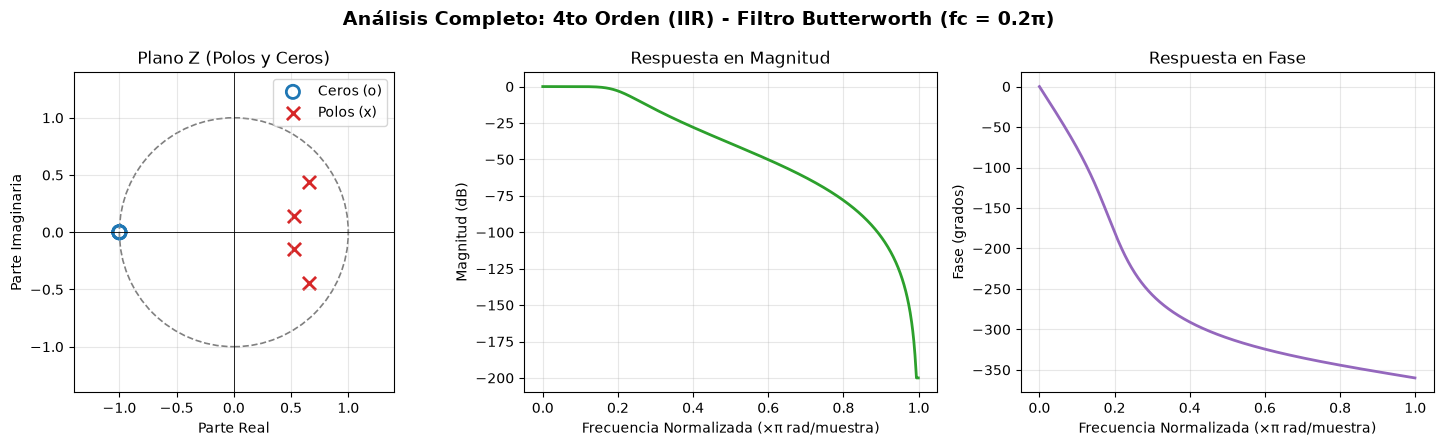

In [ ]:
b_4th, a_4th = signal.butter(4, 0.2, btype='low')
analizar_sistema(b_4th, a_4th, "4to Orden (IIR) - Filtro Butterworth (fc = 0.2π)")